# Chapitre 1 - Cours 2 : entrepôts, lacs et données dérivées

Le cours 1 a montré pourquoi l'analytique doit vivre ailleurs que dans les bases
opérationnelles. Ce notebook suit le chemin des données vers ce « ailleurs » : l'entrepôt
de données, alimenté par ETL ou ELT, puis le lac de données et ses successeurs. Il se
termine par une distinction qui servira dans tout le livre : **système de référence**
contre **données dérivées**. Sections couvertes : *Data Warehousing* (avec *From data
warehouse to data lake* et *Beyond the data lake*) et *Systems of Record and Derived
Data*.

**Plan.**

1. Les silos de données et l'entrepôt : un ETL complet, de trois bases sources à un
   schéma en étoile.
2. ETL ou ELT, et ce que l'instantané périodique ne voit pas.
3. HTAP et spécialisation : pourquoi un seul système ne fait pas tout.
4. Du data warehouse au data lake : fichiers bruts, schéma à la lecture, ingénierie des
   caractéristiques.
5. Au-delà du lac : flux d'événements et « reverse ETL ».
6. Systèmes de référence et données dérivées : reconstruire, propager, tracer.

In [1]:
import json
import re
import sqlite3
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Les silos de données et l'entrepôt (section *Data Warehousing*)

**Le problème.** Une grande organisation a des dizaines, voire des centaines de systèmes
OLTP : site marchand, caisses des magasins, stocks, logistique, fournisseurs, paie.
Chacun a son équipe, son schéma, ses conventions, et vit à peu près indépendamment des
autres. Interroger directement ces systèmes pour l'analytique pose quatre problèmes :
les données utiles sont **dispersées** (on parle de **silos**) et impossibles à combiner
en une requête ; les schémas OLTP conviennent mal à l'analyse ; les requêtes analytiques
**pénalisent** les utilisateurs (cours 1) ; et les bases OLTP sont souvent sur un réseau
auquel les analystes n'ont pas accès, pour des raisons de sécurité.

D'où l'**entrepôt de données** (« data warehouse »), apparu à la fin des années 1980 : une
base séparée, en lecture seule pour les analystes, qui contient une copie des données de
tous les systèmes OLTP. Les données y arrivent par **ETL** (*extract, transform, load*) :
extraites des bases sources (export périodique ou flux continu de modifications),
transformées en un schéma propice à l'analyse, nettoyées, puis chargées.

**Trois silos.** Construisons trois bases sources indépendantes, chacune avec ses
conventions, comme dans la vraie vie :

- le **site web** enregistre des commandes avec l'e-mail du client et des montants **en
  centimes** ;
- les **caisses** enregistrent des tickets avec le numéro de carte de fidélité, des
  montants **en euros** et des dates au format **jj/mm/aaaa** ;
- le **CRM** (gestion de la relation client) relie e-mails, cartes et segments de
  clientèle, avec quelques e-mails mal saisis (majuscules, espaces).

In [2]:
N_CUST = 300
segments = rng.choice(["étudiant", "famille", "senior", "professionnel"], N_CUST, p=[0.2, 0.4, 0.25, 0.15])
emails = [f"client{i}@exemple.fr" for i in range(N_CUST)]
cards = [f"F{100000 + 7 * i}" for i in range(N_CUST)]

crm = sqlite3.connect(":memory:")
crm.execute("CREATE TABLE contacts (contact_id INTEGER PRIMARY KEY, email TEXT, loyalty_card TEXT, segment TEXT)")
crm.executemany("INSERT INTO contacts VALUES (?, ?, ?, ?)",
                ((i, (f"  {e.upper()} " if i % 17 == 0 else e), cards[i], segments[i])
                 for i, e in enumerate(emails)))

web = sqlite3.connect(":memory:")
web.execute("CREATE TABLE orders (order_id INTEGER PRIMARY KEY, email TEXT, total_cents INTEGER, created_at TEXT)")
n_web = 3000
wc = rng.integers(0, N_CUST, n_web)
web.executemany("INSERT INTO orders VALUES (?, ?, ?, ?)",
                ((i, emails[c], int(rng.lognormal(8.3, 0.5)), f"2025-{1 + i * 3 // n_web:02d}-{1 + i % 28:02d}")
                 for i, c in enumerate(wc)))
web.execute("INSERT INTO orders VALUES (99999, 'inconnu@nulle.part', 1500, '2025-02-10')")   # client absent du CRM

pos = sqlite3.connect(":memory:")
pos.execute("CREATE TABLE tickets (ticket_no TEXT PRIMARY KEY, card TEXT, amount_eur REAL, date_fr TEXT, store TEXT)")
n_pos = 5000
pc = rng.integers(0, N_CUST, n_pos)
pos.executemany("INSERT INTO tickets VALUES (?, ?, ?, ?, ?)",
                ((f"T{i:06d}", cards[c], round(float(rng.lognormal(3.4, 0.6)), 2),
                  f"{1 + i % 28:02d}/{1 + i * 3 // n_pos:02d}/2025", f"magasin {i % 5}")
                 for i, c in enumerate(pc)))
pos.execute("INSERT INTO tickets VALUES ('T999999', NULL, 12.5, '03/02/2025', 'magasin 1')")  # client anonyme

pd.DataFrame({"source": ["CRM", "site web", "caisses"],
              "table": ["contacts", "orders", "tickets"],
              "exemple de ligne": [str(crm.execute("SELECT * FROM contacts WHERE contact_id = 17").fetchone()),
                                   str(web.execute("SELECT * FROM orders LIMIT 1").fetchone()),
                                   str(pos.execute("SELECT * FROM tickets LIMIT 1").fetchone())]})

,source,table,exemple de ligne
0,CRM,contacts,"(17, ' CLIENT17@EXEMPLE.FR ', 'F100119', 'fam..."
1,site web,orders,"(0, 'client175@exemple.fr', 2128, '2025-01-01')"
2,caisses,tickets,"('T000000', 'F101253', 28.47, '01/01/2025', 'm..."


La question d'un analyste, « quel chiffre d'affaires par segment de clientèle et par
canal, chaque mois ? », est **impossible** à poser en une requête : il faudrait joindre
trois bases différentes, sur des clés différentes (e-mail d'un côté, carte de l'autre),
avec des unités et des formats de date différents. C'est le rôle de l'ETL.

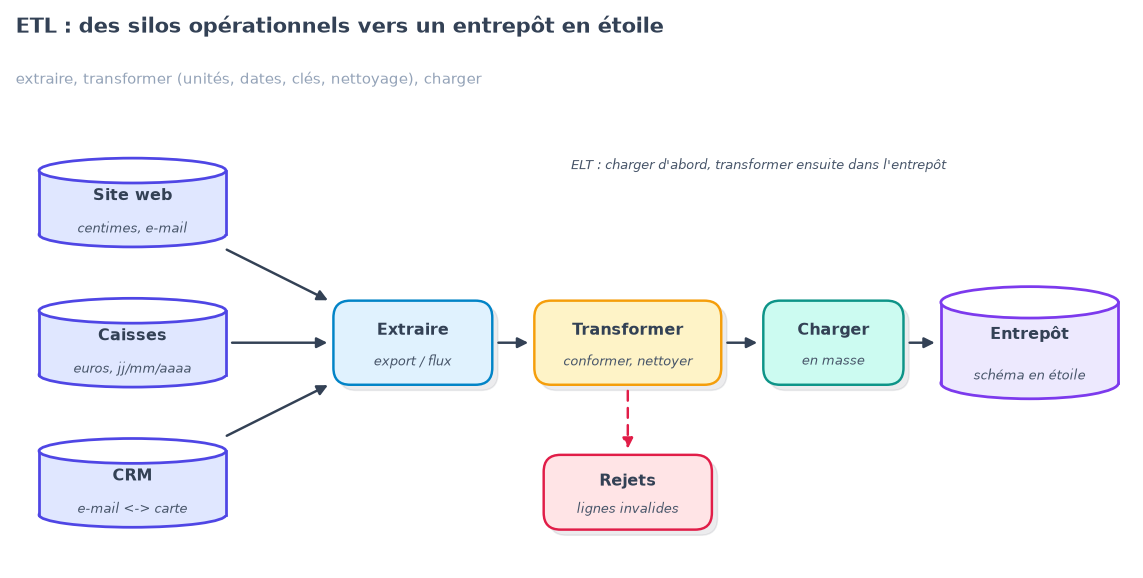

In [3]:
d = Diagram(12, 5.0, title="ETL : des silos opérationnels vers un entrepôt en étoile",
            subtitle="extraire, transformer (unités, dates, clés, nettoyage), charger")
d.box("web", 1.3, 3.9, "Site web", sub="centimes, e-mail", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("pos", 1.3, 2.4, "Caisses", sub="euros, jj/mm/aaaa", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("crm", 1.3, 0.9, "CRM", sub="e-mail <-> carte", color=INDIGO, kind="db", w=2.0, h=0.95)
d.box("x", 4.3, 2.4, "Extraire", sub="export / flux", color=SKY, w=1.7)
d.box("t", 6.6, 2.4, "Transformer", sub="conformer, nettoyer", color=AMBER, w=2.0)
d.box("l", 8.8, 2.4, "Charger", sub="en masse", color=TEAL, w=1.5)
d.box("dw", 10.9, 2.4, "Entrepôt", sub="schéma en étoile", color=VIOLET, kind="db", w=1.9, h=1.2)
for s in ("web", "pos", "crm"):
    d.arrow(s, "x")
d.arrow("x", "t"); d.arrow("t", "l"); d.arrow("l", "dw")
d.box("rej", 6.6, 0.8, "Rejets", sub="lignes invalides", color=ROSE, w=1.8, h=0.8)
d.arrow("t", "rej", style="dashed", color=ROSE)
d.note(8.0, 4.3, "ELT : charger d'abord, transformer ensuite dans l'entrepôt", fontsize=8.5)
d.show()

L'entrepôt adopte un **schéma en étoile** (détaillé au chapitre 3) : une
**table de faits** (une ligne par vente, tous canaux confondus) entourée de **tables de
dimensions** (client, date, canal). Écrivons l'ETL en Python : l'étape de transformation
est celle où se concentre le travail, et les **rejets** y sont comptés plutôt que
silencieusement ignorés.

In [4]:
def extract():
    return {"contacts": crm.execute("SELECT * FROM contacts").fetchall(),
            "orders": web.execute("SELECT * FROM orders").fetchall(),
            "tickets": pos.execute("SELECT * FROM tickets").fetchall()}


def transform(raw):
    rejects = []
    norm = lambda e: e.strip().lower()                                  # nettoyage des e-mails
    dim_customer = [(cid, segment) for cid, _, _, segment in raw["contacts"]]
    by_email = {norm(e): cid for cid, e, _, _ in raw["contacts"]}        # conformer les clés
    by_card = {card: cid for cid, _, card, _ in raw["contacts"]}
    facts = []
    for oid, email, cents, created in raw["orders"]:
        cid = by_email.get(norm(email))
        if cid is None:
            rejects.append(("site web", oid, "e-mail inconnu du CRM")); continue
        facts.append((f"W{oid}", cid, "web", created, cents / 100))           # centimes -> euros
    for tno, card, eur, date_fr in (r[:4] for r in raw["tickets"]):
        cid = by_card.get(card)
        if cid is None:
            rejects.append(("caisses", tno, "ticket sans carte de fidélité")); continue
        dd, mm, yyyy = date_fr.split("/")
        facts.append((tno, cid, "magasin", f"{yyyy}-{mm}-{dd}", eur))         # jj/mm/aaaa -> ISO
    return dim_customer, facts, rejects


def load(dw, dim_customer, facts):
    dw.executescript("""
    CREATE TABLE dim_customer (customer_key INTEGER PRIMARY KEY, segment TEXT);
    CREATE TABLE fact_sales (sale_id TEXT PRIMARY KEY, customer_key INTEGER, channel TEXT,
                             day TEXT, amount_eur REAL);
    """)
    dw.executemany("INSERT INTO dim_customer VALUES (?, ?)", dim_customer)
    dw.executemany("INSERT INTO fact_sales VALUES (?, ?, ?, ?, ?)", facts)
    dw.commit()


dw = sqlite3.connect(":memory:")
dim_customer, facts, rejects = transform(extract())
load(dw, dim_customer, facts)
print(f"{fmt(len(facts))} ventes chargées, {len(rejects)} rejet(s) :")
for r in rejects:
    print("  ", r)

8 000 ventes chargées, 2 rejet(s) :
   ('site web', 99999, 'e-mail inconnu du CRM')
   ('caisses', 'T999999', 'ticket sans carte de fidélité')


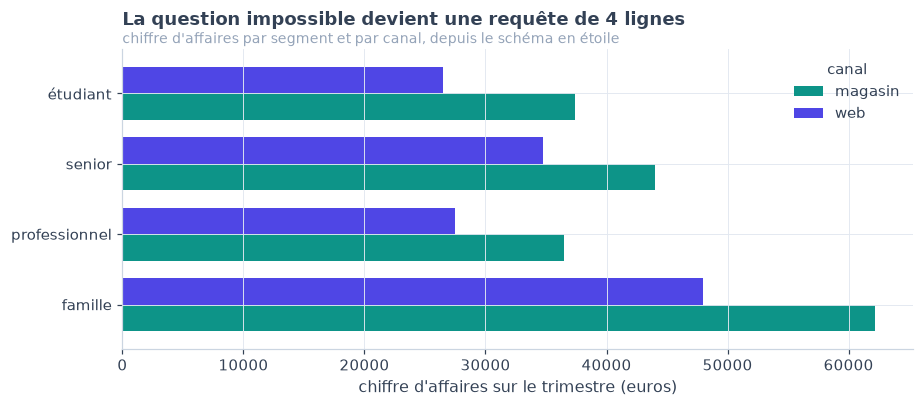

In [5]:
report = pd.read_sql("""
SELECT substr(f.day, 1, 7) AS mois, c.segment, f.channel AS canal, ROUND(SUM(f.amount_eur)) AS ca_eur
  FROM fact_sales f JOIN dim_customer c USING (customer_key)
 GROUP BY mois, c.segment, canal""", dw)
pivot = report.pivot_table(index=["segment"], columns=["canal"], values="ca_eur", aggfunc="sum")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
pivot.plot.barh(ax=ax, color=[TEAL, INDIGO], width=0.75)
ax.set_xlabel("chiffre d'affaires sur le trimestre (euros)")
ax.set_ylabel("")
ax.set_title("La question impossible devient une requête de 4 lignes")
subtitle(ax, "chiffre d'affaires par segment et par canal, depuis le schéma en étoile")
ax.legend(title="canal"); plt.tight_layout(); plt.show()

Une fois les données **conformées** (mêmes clés, mêmes unités, mêmes formats), la
question se pose en une seule requête SQL. Les deux rejets sont instructifs : une
commande d'un client absent du CRM et un ticket anonyme. Une bonne chaîne ETL ne les
jette pas en silence ; elle les compte et les signale, sinon les totaux de l'entrepôt
divergent sans explication de ceux des systèmes sources.

> **À retenir.** L'entrepôt réunit, dans un schéma pensé pour l'analyse, une copie en
> lecture seule des données de tous les systèmes OLTP. L'essentiel du travail est la
> transformation : conformer les clés, les unités et les formats, nettoyer, rendre compte
> des rejets.